In [23]:
import pandas as pd

features = pd.read_csv('data/books_features.csv', dtype={'error': 'string'})
gr = pd.read_csv('data/GoodReads_100k_books.csv')

display(features.head(2))
display(gr.head(2))

valid_features = features[features['error'] != '<NA>']

print(f'Books in features {len(valid_features)}')
print(f'Books in gr {len(gr)}')

,isbn,error,color1_hex,color1_pct,color2_hex,color2_pct,color3_hex,color3_pct,text_color_hex,text_color_conf,contrast_rms,contrast_wcag_p5_p95,contrast_top2_deltaE,edge_density,mean_gradient,hf_energy_ratio,color_entropy,mean_lightness,mean_saturation,colorfulness
0,0002005018,<NA>,#3d342d,0.2099,#d2694d,0.2067,#a35e4e,0.1830,#d99772,0.392,0.2099,10.363,57.45,0.2406,0.0573,0.3535,6.899,0.5102,0.4249,0.2685
1,0374157065,<NA>,#efeead,0.3233,#f3f5d9,0.2920,#e2dc72,0.1636,#34424b,0.887,0.2254,9.954,18.95,0.3344,0.0832,0.1741,7.162,0.8187,0.2990,0.2273


,author,bookformat,desc,genre,img,isbn,isbn13,link,pages,rating,reviews,title,totalratings
0,Laurence M. Hauptman,Hardcover,Reveals that several hundred thousand Indians ...,"History,Military History,Civil War,American Hi...",https://i.gr-assets.com/images/S/compressed.ph...,002914180X,9.78E+12,https://goodreads.com/book/show/1001053.Betwee...,0,3.52,5,Between Two Fires: American Indians in the Civ...,33
1,"Charlotte Fiell,Emmanuelle Dirix",Paperback,Fashion Sourcebook - 1920s is the first book i...,"Couture,Fashion,Historical,Art,Nonfiction",https://i.gr-assets.com/images/S/compressed.ph...,1906863482,9.78E+12,https://goodreads.com/book/show/10010552-fashi...,576,4.51,6,Fashion Sourcebook 1920s,41


Books in features 96423
Books in gr 100000


In [20]:
df1 = features.copy()
df2 = gr.copy()
# Clean and handle case sensitivity for 'X'
df1['isbn_clean'] = df1['isbn'].astype(str).str.strip().str.upper()

# Drop the float decimal and force uppercase
df2['isbn_clean'] = df2['isbn'].astype(str).str.strip().str.split('.').str[0].str.upper()

# Now apply your padding and match
df1['isbn_clean'] = df1['isbn_clean'].str.zfill(10)
df2['isbn_clean'] = df2['isbn_clean'].str.zfill(10)

overlap_count = df1['isbn_clean'].isin(df2['isbn_clean']).sum()
print(f"Overlapping ISBN count: {overlap_count}")
oc = df1['isbn_clean'].isin(df2['isbn_clean']).value_counts()
display(oc)


Overlapping ISBN count: 8785


isbn_clean
False    262594
True       8785
Name: count, dtype: int64

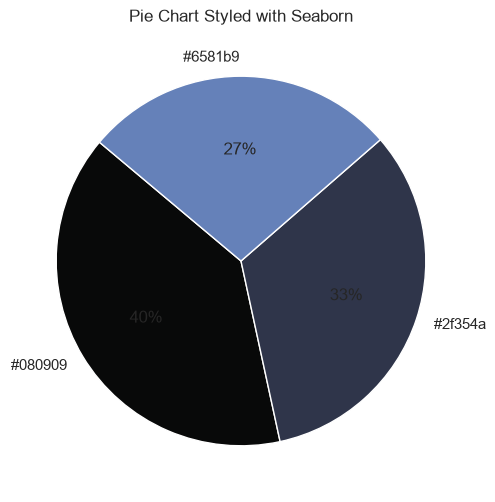

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

#080909,0.2765,#2f354a,0.231,#6581b9,0.1924
data = [0.2765,0.231,0.1924]
labels = ['#080909','#2f354a','#6581b9']

sns.set_theme(style="whitegrid")
# colors = sns.color_palette('pastel')[0:len(data)]

plt.figure(figsize=(6, 6))
plt.pie(
    data,
    labels=labels,
    colors=labels,
    autopct='%.0f%%', # Displays integer percentages
    startangle=140    # Rotates the start point for better layout
)

plt.title('Pie Chart Styled with Seaborn')
plt.show()

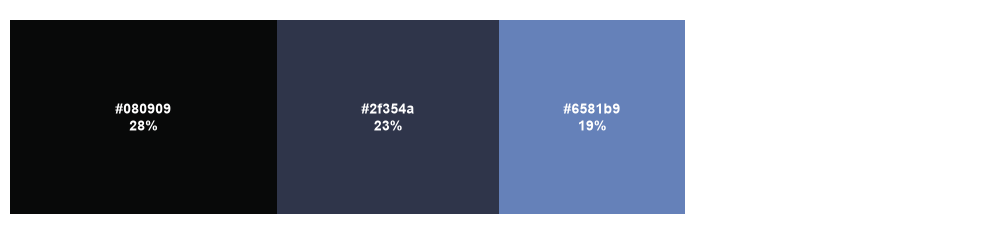

In [32]:
import matplotlib.pyplot as plt

# colors = ["#2b5c8f", "#d57a66", "#eac435", "#ffffff"]
# percentages = [40, 30, 20, 10]  # Make sure these add up to 100

percentages = [27.65,23.1,19.24]
colors = ['#080909','#2f354a','#6581b9']

fig, ax = plt.subplots(figsize=(10, 2.5))

left = 0
for color, pct in zip(colors, percentages):
    # Plot the specific bar segment
    ax.barh(0, pct, left=left, color=color, edgecolor='none')

    # Calculate the center of the current segment for text positioning
    text_x = left + pct / 2

    # Simple luminance formula to automatically pick readable text color (Black vs White)
    # Strips the '#' and converts hex values to RGB to check brightness
    rgb = [int(color.lstrip('#')[i:i+2], 16) for i in (0, 2, 4)]
    luminance = (0.299 * rgb[0] + 0.587 * rgb[1] + 0.114 * rgb[2]) / 255
    text_color = 'black' if luminance > 0.5 else 'white'

    # Create a two-line label: Hex Code on top, Percentage underneath
    label = f"{color}\n{pct:.0f}%"

    # Place the text only if the segment is wide enough to fit it cleanly
    if pct >= 5:
        ax.text(
            text_x, 0, label,
            ha='center', va='center',
            color=text_color, fontweight='bold', fontsize=10,
            linespacing=1.3
        )

    # Shift the starting point for the next segment
    left += pct

# Strip the outer graph formatting to keep it clean and unified
ax.set_xlim(0, 100)
ax.axis('off')

plt.tight_layout()
plt.show()